In [2]:
%config Completer.use_jedi = True

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split 

In [3]:
df=pd.read_csv('train.csv')

In [53]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [35]:
num_df=df.select_dtypes(include='number')
cat_df=df.select_dtypes(include='string')
num_df.columns

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')

In [38]:
co=num_df.corr()['SalePrice']*100
for i in co.index:
    if co[i]< -3:
        print(i,co[i])
    if co[i]> 25:
        print(i,co[i])

MSSubClass -8.428413512659509
LotFrontage 35.17990965706774
LotArea 26.38433538714051
OverallQual 79.09816005838053
OverallCond -7.785589404867797
YearBuilt 52.289733287949666
YearRemodAdd 50.71009671113866
MasVnrArea 47.74930470957145
BsmtFinSF1 38.64198062421535
TotalBsmtSF 61.35805515591943
1stFlrSF 60.585218469191524
2ndFlrSF 31.933380283206738
GrLivArea 70.86244776126514
FullBath 56.06637627484453
HalfBath 28.410767559478256
KitchenAbvGr -13.590737084214105
TotRmsAbvGrd 53.37231555820284
Fireplaces 46.692883675152764
GarageYrBlt 48.63616774878596
GarageCars 64.04091972583518
GarageArea 62.34314389183622
WoodDeckSF 32.44134445681293
OpenPorchSF 31.585622711605506
EnclosedPorch -12.857795792595661
SalePrice 100.0


In [87]:
X=pd.concat([num_df.iloc[:,[1,2,3,4,5,6,7,12,13,16,19,27]],cat_df.iloc[:,8:9]],axis=1)
y=num_df.iloc[:,-1]
X

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,1stFlrSF,GrLivArea,FullBath,GarageArea,Neighborhood
0,60,65.0,8450,7,5,2003,2003,856,856,1710,2,548,CollgCr
1,20,80.0,9600,6,8,1976,1976,1262,1262,1262,2,460,Veenker
2,60,68.0,11250,7,5,2001,2002,920,920,1786,2,608,CollgCr
3,70,60.0,9550,7,5,1915,1970,756,961,1717,1,642,Crawfor
4,60,84.0,14260,8,5,2000,2000,1145,1145,2198,2,836,NoRidge
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,62.0,7917,6,5,1999,2000,953,953,1647,2,460,Gilbert
1456,20,85.0,13175,6,6,1978,1988,1542,2073,2073,2,500,NWAmes
1457,70,66.0,9042,7,9,1941,2006,1152,1188,2340,2,252,Crawfor
1458,20,68.0,9717,5,6,1950,1996,1078,1078,1078,1,240,NAmes


In [88]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor

In [89]:
X_train,X_test,y_train,y_test=train_test_split(X.drop(columns='MSSubClass'),y,test_size=0.25,random_state=42)

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
X_train

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,1stFlrSF,GrLivArea,FullBath,GarageArea,Neighborhood
1023,43.0,3182,7,5,2005,2006,1346,1504,1504,2,437,Blmngtn
810,78.0,10140,6,6,1974,1999,1040,1309,1309,1,484,NWAmes
1384,60.0,9060,6,5,1939,1950,560,698,1258,1,280,Edwards
626,NaN,12342,5,5,1960,1978,978,1422,1422,1,286,NAmes
813,75.0,9750,6,6,1958,1958,1442,1442,1442,1,301,NAmes
...,...,...,...,...,...,...,...,...,...,...,...,...
1095,78.0,9317,6,5,2006,2006,1314,1314,1314,2,440,CollgCr
1130,65.0,7804,4,3,1928,1950,1122,1328,1981,2,576,SWISU
1294,60.0,8172,5,7,1955,1990,864,864,864,1,572,Edwards
860,55.0,7642,7,8,1918,1998,912,912,1426,1,216,Crawfor


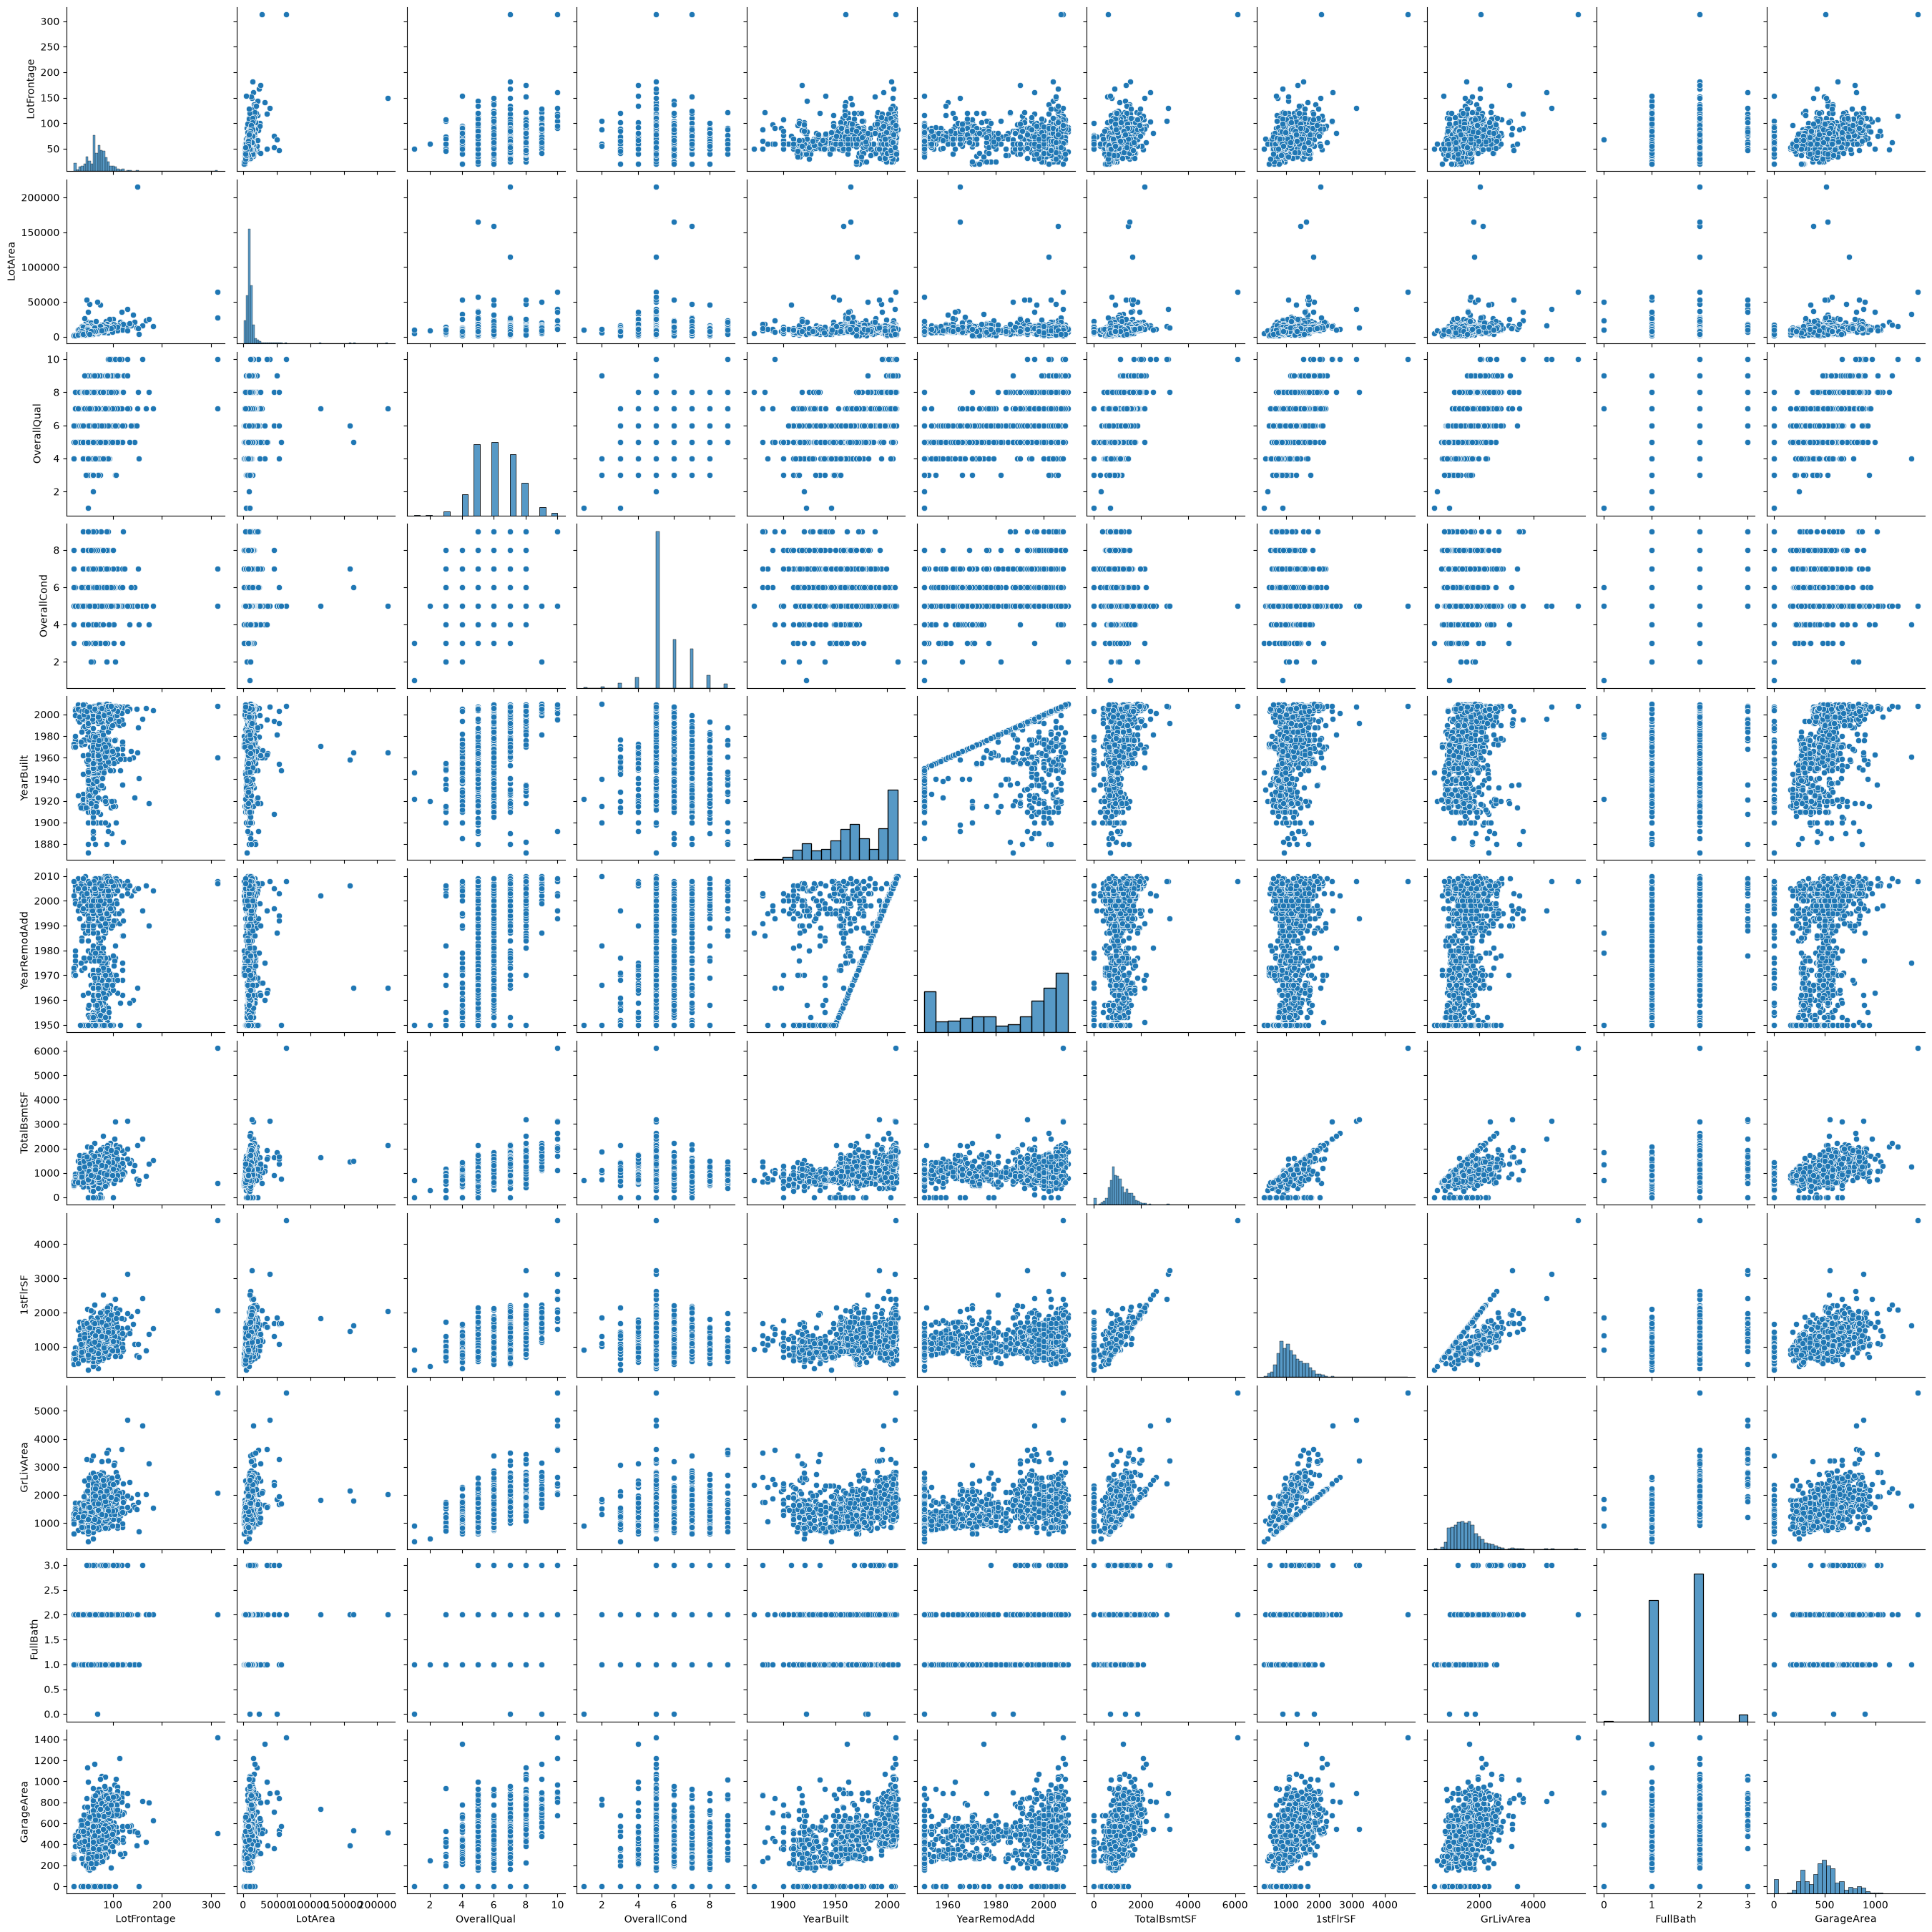

In [91]:
sns.pairplot(X_train.drop(columns=['Neighborhood']))
plt.show()

In [92]:
num_features=['OverallQual','OverallCond','YearBuilt','YearRemodAdd','TotalBsmtSF','1stFlrSF','GrLivArea','FullBath','GarageArea']
num_pipeline=Pipeline([
    ('num1',SimpleImputer(strategy='median')),
    ('num2',StandardScaler())
])
log_pipeline=Pipeline([
    ('log1',SimpleImputer(strategy='median')),
    ('log2',FunctionTransformer(np.log1p)),
    ('log3',StandardScaler())
])
cat_pipeline=Pipeline([
    ('cat1',SimpleImputer(strategy='most_frequent')),
    ('cat2',OneHotEncoder(drop='first',handle_unknown='ignore'))
])
t=ColumnTransformer(
    transformers=[
        ('trf1',log_pipeline,['LotFrontage','LotArea']),
        ('trf2',num_pipeline,num_features),
        ('trf3',cat_pipeline,['Neighborhood'])
    ]
)
model_pipeline=Pipeline([
    ('preprocessor',t),
    ('model', SGDRegressor(max_iter=100,tol=1e-3,random_state=42))
])
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

In [93]:
from sklearn.metrics import r2_score,mean_absolute_error
r2_score(y_test,y_pred), mean_absolute_error(y_test, y_pred)

(0.8370141769582473, 20563.17683849547)

In [94]:
print(y_test.describe())
print(y_pred.min(), y_pred.max())


count       365.000000
mean     178547.923288
std       83812.614843
min       35311.000000
25%      128200.000000
50%      155000.000000
75%      207000.000000
max      755000.000000
Name: SalePrice, dtype: float64
14568.876662939088 461260.1800396863


In [95]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

comparison['Absolute_Error'] = abs(
    comparison['Actual'] - comparison['Predicted']
)

comparison.sort_values(
    'Absolute_Error', ascending=False
).head(10)

,Actual,Predicted,Absolute_Error
691,755000,461260.180040,293739.819960
898,611657,362998.989397,248658.010603
1046,556581,362595.025953,193985.974047
1243,465000,363525.942391,101474.057609
581,253293,342003.955994,88710.955994
591,451950,367203.964756,84746.035244
585,369900,289872.459598,80027.540402
231,403000,324704.173536,78295.826464
774,395000,322156.970735,72843.029265
58,438780,368837.063073,69942.936927


In [96]:
import pickle
pickle_model_path='model.pkl'
with open(pickle_model_path,'wb') as f:
    pickle.dump(model_pipeline,f)